# 02 – Results: model comparison, errors and ROC curves

This notebook uses the code in `src/` to show the results. The heavy lifting (data cleaning, pipeline, cross-validation, tuning) lives in `src/`; here we only look at the outputs.

All numbers come from **cross-validation on the 302 unique patients**. There is no separate test set (see the limitations section in the README).

In [1]:
import sys
sys.path.append("..")

import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import confusion_matrix, roc_auc_score, roc_curve
from sklearn.model_selection import cross_val_predict

from src.data import load_clean
from src.evaluate import CV
from src.tune import SEARCHES, make_search

warnings.filterwarnings("ignore", category=ConvergenceWarning)

FIG_DIR = Path("../reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

# One fixed colour per model (same order everywhere)
COLORS = {"Logistic Regression": "#2a78d6", "Random Forest": "#eb6834",
          "SVM (RBF kernel)": "#1baf7a", "XGBoost": "#eda100"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e5e1", "axes.axisbelow": True})

X, y = load_clean()

## 1. Cross-validation results

Saved by `python -m src.compare_models` (default settings) and `python -m src.tune` (tuned with nested CV). Mean ± standard deviation over the 5 outer test folds.

In [2]:
def as_table(path):
    df = pd.read_csv(path, index_col="model")
    table = pd.DataFrame(index=df.index)
    for m in ["accuracy", "precision", "recall", "f1", "roc_auc"]:
        table[m] = [f"{a:.3f} ± {s:.3f}" for a, s in zip(df[f"{m}_mean"], df[f"{m}_std"])]
    table["train acc."] = df["train_accuracy"].round(3)
    return table

print("Default settings:")
display(as_table("../reports/cv_results_default.csv"))
print("Tuned (nested CV):")
display(as_table("../reports/cv_results_tuned.csv"))

Default settings:


,accuracy,precision,recall,f1,roc_auc,train acc.
model,,,,,,
Baseline (always 'no disease'),0.543 ± 0.007,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.500 ± 0.000,0.543
Logistic Regression,0.848 ± 0.028,0.868 ± 0.095,0.804 ± 0.077,0.829 ± 0.024,0.917 ± 0.025,0.876
Random Forest,0.815 ± 0.035,0.807 ± 0.053,0.790 ± 0.087,0.795 ± 0.043,0.907 ± 0.017,1.000
SVM (RBF kernel),0.835 ± 0.019,0.865 ± 0.065,0.768 ± 0.094,0.808 ± 0.032,0.907 ± 0.024,0.911
XGBoost,0.805 ± 0.044,0.797 ± 0.059,0.776 ± 0.067,0.784 ± 0.045,0.878 ± 0.022,1.000


Tuned (nested CV):


,accuracy,precision,recall,f1,roc_auc,train acc.
model,,,,,,
Logistic Regression,0.854 ± 0.019,0.887 ± 0.078,0.797 ± 0.075,0.833 ± 0.017,0.920 ± 0.019,0.873
Random Forest,0.831 ± 0.030,0.851 ± 0.080,0.783 ± 0.072,0.809 ± 0.028,0.918 ± 0.012,0.878
SVM (RBF kernel),0.854 ± 0.033,0.903 ± 0.093,0.783 ± 0.072,0.831 ± 0.033,0.920 ± 0.017,0.873
XGBoost,0.835 ± 0.033,0.850 ± 0.073,0.790 ± 0.089,0.812 ± 0.041,0.905 ± 0.019,0.900


**Final model: Logistic Regression.** It is tied with the SVM for the best accuracy and ROC-AUC, and the difference to the other models is within the fold-to-fold noise. I chose it because it is the simplest, its tuned setting was stable (C = 0.1 in 4 of 5 folds), it gives probabilities directly, and its weights can be explained.

## 2. Out-of-fold predictions

To draw a confusion matrix and ROC curve from cross-validation, I use `cross_val_predict`. It returns, for every patient, the prediction made by the model that was **not** trained on that patient (the patient was in that fold's test set). Each model is still tuned with GridSearchCV inside each fold, exactly as in `src/tune.py`.

For Logistic Regression, Random Forest and XGBoost the score is the predicted probability of disease. The SVM has no probabilities by default, so its score is the distance from the decision boundary. ROC curves only need the *ranking* of patients, so both work.

In [3]:
oof_scores = {}
for name, (model, grid) in SEARCHES.items():
    method = "decision_function" if name.startswith("SVM") else "predict_proba"
    pred = cross_val_predict(make_search(model, grid), X, y, cv=CV, method=method)
    oof_scores[name] = pred[:, 1] if method == "predict_proba" else pred
    print(f"{name:20s} done")

FINAL = "Logistic Regression"
proba = oof_scores[FINAL]   # out-of-fold probability of disease for each patient

Logistic Regression  done


Random Forest        done


SVM (RBF kernel)     done


XGBoost              done


## 3. Confusion matrix (final model, cut-off 0.5)

The model predicts "disease" when the probability is at least 0.5.

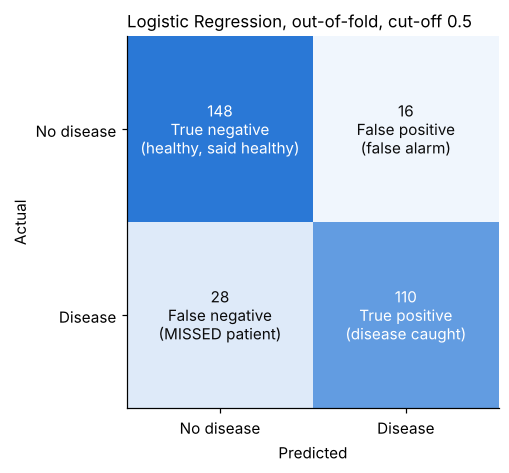

Disease patients: 138.  Caught: 110.  Missed: 28.  Recall = 0.797
Flagged as disease: 126.  Correct: 110.  False alarms: 16.  Precision = 0.873


In [4]:
y_pred = (proba >= 0.5).astype(int)
cm = confusion_matrix(y, y_pred)
tn, fp, fn, tp = cm.ravel()

blues = LinearSegmentedColormap.from_list("blues", ["#f0f6fd", "#2a78d6"])
fig, ax = plt.subplots(figsize=(5.2, 4.4))
ax.imshow(cm, cmap=blues)
ax.grid(False)
names = [["True negative\n(healthy, said healthy)", "False positive\n(false alarm)"],
         ["False negative\n(MISSED patient)", "True positive\n(disease caught)"]]
for i in range(2):
    for j in range(2):
        color = "white" if cm[i, j] > cm.max() / 2 else "#0b0b0b"
        ax.text(j, i, f"{cm[i, j]}\n{names[i][j]}", ha="center", va="center",
                fontsize=10, color=color)
ax.set_xticks([0, 1], ["No disease", "Disease"])
ax.set_yticks([0, 1], ["No disease", "Disease"])
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.set_title("Logistic Regression, out-of-fold, cut-off 0.5", loc="left", fontsize=11)
fig.tight_layout()
fig.savefig(FIG_DIR / "confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Disease patients: {tp + fn}.  Caught: {tp}.  Missed: {fn}.  Recall = {tp / (tp + fn):.3f}")
print(f"Flagged as disease: {tp + fp}.  Correct: {tp}.  False alarms: {fp}.  Precision = {tp / (tp + fp):.3f}")

These pooled numbers are close to, but not exactly, the fold averages in the table above (there we averaged 5 fold scores; here all 302 predictions are counted together).

## 4. ROC curves

An ROC curve shows every possible cut-off at once: for each cut-off, how many sick patients are caught (true positive rate = recall) against how many healthy patients get a false alarm (false positive rate). The closer the curve is to the top-left corner, the better. The dashed diagonal is random guessing (AUC = 0.5).

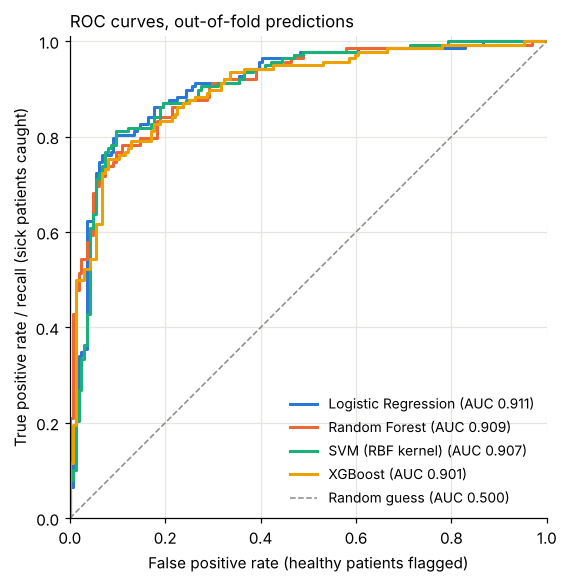

In [5]:
fig, ax = plt.subplots(figsize=(6, 5.4))
for name, scores in oof_scores.items():
    fpr, tpr, _ = roc_curve(y, scores)
    auc = roc_auc_score(y, scores)
    ax.plot(fpr, tpr, linewidth=2, color=COLORS[name], label=f"{name} (AUC {auc:.3f})")
ax.plot([0, 1], [0, 1], linestyle="--", color="#8a8984", linewidth=1, label="Random guess (AUC 0.500)")
ax.set_xlabel("False positive rate (healthy patients flagged)")
ax.set_ylabel("True positive rate / recall (sick patients caught)")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.01)
ax.set_aspect("equal")
ax.legend(loc="lower right", frameon=False, fontsize=9)
ax.set_title("ROC curves, out-of-fold predictions", loc="left", fontsize=11)
fig.tight_layout()
fig.savefig(FIG_DIR / "roc_curves.png", dpi=150, bbox_inches="tight")
plt.show()

The four curves lie almost on top of each other, which matches the table: on this data the choice of model matters much less than the size of the data.

The AUC values in the legend (e.g. 0.911 for Logistic Regression) are a little lower than the table (0.920). The table averages the AUC of each fold separately; the plot pools all 302 out-of-fold predictions into one curve. Pooling mixes scores from 5 slightly different models, which usually lowers AUC a little. Both are valid; the README reports the fold average.

## 5. Choosing the cut-off: recall vs false alarms

With the default cut-off of 0.5, the model misses some sick patients. In screening, a missed patient is usually worse than a false alarm, so one option is to lower the cut-off. The table shows the trade-off.

In [6]:
rows = []
for cut in [0.5, 0.4, 0.3, 0.2]:
    pred = (proba >= cut).astype(int)
    tn_, fp_, fn_, tp_ = confusion_matrix(y, pred).ravel()
    rows.append({"cut-off": cut,
                 "recall": round(tp_ / (tp_ + fn_), 3),
                 "precision": round(tp_ / (tp_ + fp_), 3),
                 "missed patients (FN)": fn_,
                 "false alarms (FP)": fp_,
                 "accuracy": round((tp_ + tn_) / len(y), 3)})
pd.DataFrame(rows).set_index("cut-off")

,recall,precision,missed patients (FN),false alarms (FP),accuracy
cut-off,,,,,
0.5,0.797,0.873,28,16,0.854
0.4,0.841,0.806,22,28,0.834
0.3,0.913,0.724,12,48,0.801
0.2,0.964,0.646,5,73,0.742


Lowering the cut-off catches more sick patients but creates more false alarms. Which cut-off is "right" is a clinical decision about costs, not something the data can decide. Also, I picked these cut-offs while looking at the same cross-validation predictions, so the numbers for a lower cut-off are a rough guide, not a validated result.

**What I do in this project:** the Flask app returns the **probability**, not only a yes/no, and keeps the standard 0.5 cut-off for the label. A real screening tool would need its cut-off chosen with clinicians and checked on new patients.

## 6. Which features drive the predictions?

I use two methods:

1. **Permutation importance** (main answer). Take a trained model and a test fold. Randomly shuffle one column, so that feature no longer carries any real information, and see how much the ROC-AUC drops. A big drop means the model relies on that feature. I do this inside the same 5-fold CV, always on the **test** fold, so it measures what matters for unseen patients. It works on the 13 original features, so e.g. all `cp` columns are shuffled together.
2. **Logistic Regression weights** of the final model. They show the *direction*: does a feature raise or lower the predicted risk?

I did not use SHAP. For a linear model, SHAP values are essentially the weights times the (scaled) feature values, so they would add a library but little new information.

In [7]:
from sklearn.inspection import permutation_importance

model, grid = SEARCHES[FINAL]
fold_importances = []
for train_idx, test_idx in CV.split(X, y):
    fitted = make_search(model, grid).fit(X.iloc[train_idx], y.iloc[train_idx])
    result = permutation_importance(fitted, X.iloc[test_idx], y.iloc[test_idx],
                                    scoring="roc_auc", n_repeats=20, random_state=0)
    fold_importances.append(result.importances_mean)

imp = pd.DataFrame(fold_importances, columns=X.columns)
summary = pd.DataFrame({"mean drop in ROC-AUC": imp.mean(), "std over folds": imp.std()})
summary = summary.sort_values("mean drop in ROC-AUC", ascending=False)
summary.round(3)

,mean drop in ROC-AUC,std over folds
ca,0.060,0.026
thal,0.030,0.013
cp,0.026,0.006
sex,0.011,0.011
thalach,0.006,0.010
slope,0.006,0.010
oldpeak,0.006,0.007
trestbps,0.002,0.009
exang,0.002,0.009
restecg,0.001,0.002


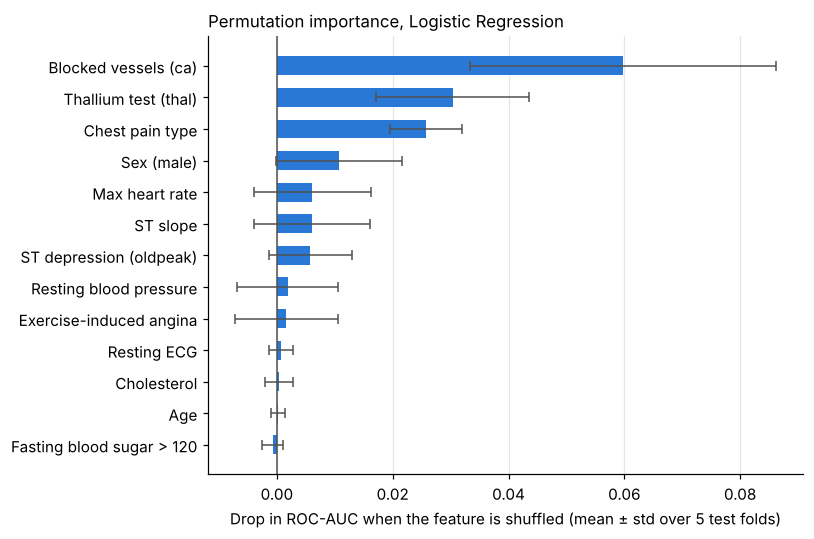

In [8]:
plain = {"age": "Age", "sex": "Sex (male)", "cp": "Chest pain type", "trestbps": "Resting blood pressure",
         "chol": "Cholesterol", "fbs": "Fasting blood sugar > 120", "restecg": "Resting ECG",
         "thalach": "Max heart rate", "exang": "Exercise-induced angina", "oldpeak": "ST depression (oldpeak)",
         "slope": "ST slope", "ca": "Blocked vessels (ca)", "thal": "Thallium test (thal)"}

s = summary.iloc[::-1]   # largest at the top of the plot
fig, ax = plt.subplots(figsize=(7.5, 5))
ax.barh([plain[f] for f in s.index], s["mean drop in ROC-AUC"], xerr=s["std over folds"],
        color="#2a78d6", height=0.6, error_kw={"ecolor": "#52514e", "linewidth": 1, "capsize": 3})
ax.axvline(0, color="#52514e", linewidth=1)
ax.set_xlabel("Drop in ROC-AUC when the feature is shuffled (mean ± std over 5 test folds)")
ax.set_title("Permutation importance, Logistic Regression", loc="left", fontsize=11)
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "permutation_importance.png", dpi=150, bbox_inches="tight")
plt.show()

### Weights of the final model

The final model is trained on all 302 patients by `python -m src.train_final` (C = 0.1) and saved to `models/heart_pipeline.joblib`. Red bars raise the predicted risk, blue bars lower it.

How to read the size of a weight:
- For **numeric** features (scaled), the weight is the change in log-odds for one standard deviation more.
- For **yes/no** features, it is the change for "yes" compared with "no".
- For **one-hot categories** like `cp`, compare the categories of the same feature with each other, e.g. "asymptomatic" vs "non-anginal".

Because of these different scales, the weights are good for **direction**, and permutation importance is better for **how much** a feature matters.

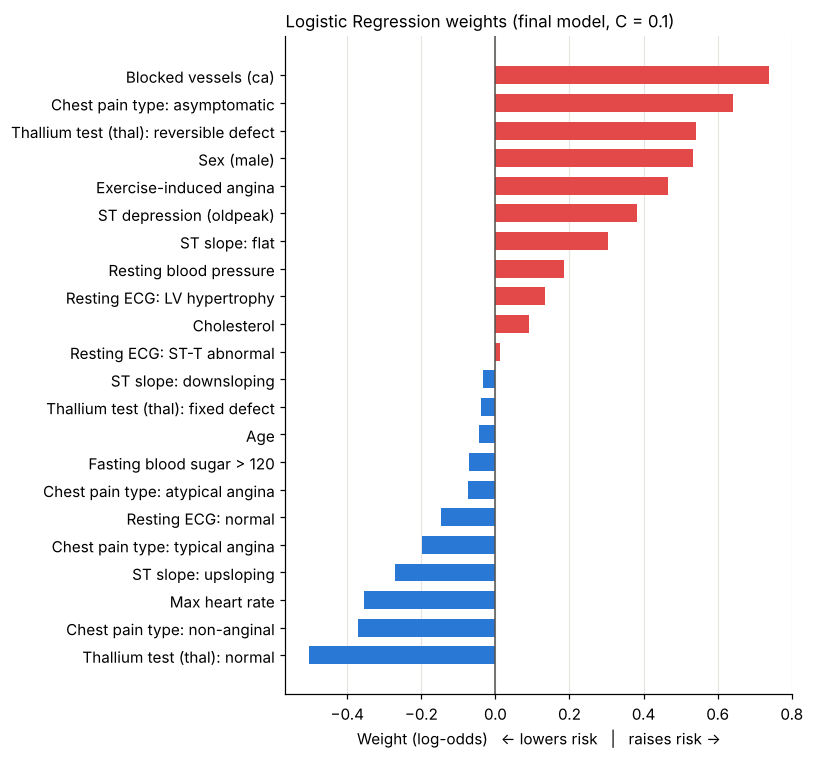

In [9]:
import joblib

final = joblib.load("../models/heart_pipeline.joblib")
names = final.named_steps["prep"].get_feature_names_out()
weights = pd.Series(final.named_steps["model"].coef_[0], index=names)

# Readable labels for the 22 columns
cat_labels = {"cp": {0: "asymptomatic", 1: "atypical angina", 2: "non-anginal", 3: "typical angina"},
              "restecg": {0: "LV hypertrophy", 1: "normal", 2: "ST-T abnormal"},
              "slope": {0: "downsloping", 1: "flat", 2: "upsloping"},
              "thal": {1: "fixed defect", 2: "normal", 3: "reversible defect"}}
def label(col):
    kind, name = col.split("__")
    if kind == "cat":
        feat, val = name.rsplit("_", 1)
        return f"{plain[feat]}: {cat_labels[feat][int(float(val))]}"
    return plain[name]

weights.index = [label(c) for c in weights.index]
weights = weights.sort_values()

fig, ax = plt.subplots(figsize=(7.5, 7))
colors = ["#e34948" if w > 0 else "#2a78d6" for w in weights]
ax.barh(weights.index, weights, color=colors, height=0.65)
ax.axvline(0, color="#52514e", linewidth=1)
ax.set_xlabel("Weight (log-odds)   ← lowers risk   |   raises risk →")
ax.set_title("Logistic Regression weights (final model, C = 0.1)", loc="left", fontsize=11)
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "logreg_weights.png", dpi=150, bbox_inches="tight")
plt.show()

### What drives the predictions

- **Three features clearly matter most:** the number of blocked vessels (`ca`), the thallium test (`thal`) and chest pain type (`cp`). Shuffling `ca` alone lowers ROC-AUC by about 0.06. In the weights, more blocked vessels, a reversible thallium defect and *asymptomatic* chest pain raise the risk; a normal thallium result and non-anginal chest pain lower it.
- **Sex** comes next (male raises the risk in this sample), but its error bar is as large as its value.
- **Max heart rate, ST depression, ST slope and exercise angina** each have a small importance. This looks strange, because in the EDA they were among the features most correlated with disease. The reason is that they are **moderately correlated with each other** (correlations of about 0.3 to 0.6; they all come from the same exercise test). When one of them is shuffled, the model still gets similar information from the others, so the score hardly drops. Low permutation importance means "the model can do without this one feature", not "this feature is unrelated to disease". The weights confirm they still point the expected way (lower max heart rate, more ST depression, a flat slope and exercise angina all raise the risk).
- **Cholesterol, age and fasting blood sugar** have importance close to zero. Removing them would barely change the model.
- For most features the standard deviation is about as large as the mean, so only the top three are clearly separated from zero. With 302 patients, the exact order of the smaller features should not be over-interpreted.

These patterns agree with what is generally known about this data (blocked vessels and stress-test results are strong signals), which is a useful sanity check. They describe what **this model** uses, not what causes heart disease.

## 7. Limitations

This is a student project for learning, **not a medical tool**. It must not be used to diagnose or rule out heart disease.

1. **Small dataset.** After removing duplicates there are only 302 patients. Scores move by about ±2–3 percentage points between folds, and by a similar amount just by shuffling the folds differently. The differences between the four models are inside this noise.
2. **No external validation.** All numbers come from cross-validation on the same dataset. The model has never been tested on patients from another hospital or time period, so its real-world performance is unknown and probably lower. A natural next step would be to test it on the other UCI heart disease sets (Hungary, Switzerland, Long Beach VA), which have the same features but many more missing values.
3. **Old data from one clinic.** The data was collected at the Cleveland Clinic and donated to UCI in 1988. Patients, tests and treatment have changed since then.
4. **A selected group of patients.** Every patient had a coronary angiogram (this is where the label comes from), so they were already suspected of heart disease. About 46% have disease, much more than in the general population. In a general screening setting the precision would be much lower.
5. **Not balanced across groups.** Only 96 of 302 patients are women and the age range is 29–77. The model may work worse for groups that are rare in the data, and I did not have enough data to check this reliably.
6. **The most important features need hospital tests.** The top feature, `ca`, is counted on fluoroscopy, and `thal` comes from a thallium stress test. These are specialised tests, so the model cannot be used with simple measurements, and some of this information may only be available close to the moment the diagnosis is made anyway.
7. **Data quality of the Kaggle file.** The Kaggle version had 723 duplicate rows, reversed labels and missing values stored as fake categories. I fixed these by checking against the original UCI file, but it shows that a popular dataset should not be trusted without checking.
8. **Cut-off and probabilities.** The app uses the standard 0.5 cut-off. A real tool would need the cut-off chosen with clinicians, and I did not check whether the predicted probabilities are well calibrated (for example, whether "70% risk" really means 7 in 10 such patients have disease).